# ML1 - GridSearch avec DecisionTreeRegression, RandomForestRegressor

Ce notebook fait suite au notebook ML1_Pipeline_Model et se concentre sur :
1. L'utilisation de DecisionTreeRegressor et RandomForestRegressor ou d'autres
2. L'optimisation des hyperparamètres avec GridSearchCV
3. La validation croisée (cross-validation)

## 1. Import des bibliothèques

In [105]:
# Les libraries nécessaires
import pandas as pd
import seaborn as sns
import numpy as np
import scipy.stats as sp
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

from sklearn.compose import ColumnTransformer

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, cross_validate
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.linear_model import LassoCV, Ridge

from sklearn.feature_selection import SelectFromModel

from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

from sklearn.tree import DecisionTreeRegressor

from tabicl import TabICLRegressor

## 2. Chargement et préparation des données avec le PipeLine.

Nous reprenons les mêmes étapes de préparation que dans le notebook précédent.

In [ ]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')
#df = df.query('anneedeplantation > 1960')

df['Latitude'] = df['Latitude'].map(lambda x:float(x))
df['Longitude'] = df['Longitude'].map(lambda x:float(x))
df['adr_secteur'] = df['adr_secteur'].map(lambda x:str(x))
df['taxon'] = df['genre_bota']+ ' ' + df['espece'].fillna('sp.')

df = df.drop(['sous_categorie_desc', 'collectivite', 'portarbre', 'genre_bota', 'espece'], axis=1)
annee = df.pop('anneedeplantation')

X_train, X_test, y_train, y_test = train_test_split(df, annee, random_state=28)

cat_var = df.select_dtypes(include=str).columns.tolist()
num_var = df.select_dtypes(exclude=str).columns.tolist()

transformer = ColumnTransformer([
    ("num_std", StandardScaler(), num_var),
     ("cat_std", OneHotEncoder(handle_unknown='ignore'), cat_var)
])


## 3. Cross-validation initiale

Avant d'optimiser les hyperparamètres, évaluons un modèle avec les paramètres par défaut en utilisant la validation croisée.

In [3]:
# Validation croisée initiale sans optimisation des hyperparamètres
# On peut aussi imprimer les scores MSE ou MAE de chaque cross-validation.

model_0 = Pipeline([
    ("prep", transformer),
    ("rfg", RandomForestRegressor(max_depth=20, random_state=28)),
])

model_0.fit(X_train, y_train)            # données BRUTES : le pipeline prépare lui-même
cv0 = cross_validate(model_0, X_train, y_train, cv=5,  scoring='neg_root_mean_squared_error', return_train_score=True)   # le transformer est ré-ajusté dans chaque pli

In [4]:
print(f"Train RMSE : {-cv0['train_score'].mean():.2f}")
print(f"CV RMSE    : {-cv0['test_score'].mean():.2f} ± {cv0['test_score'].std():.2f}")

Train RMSE : 3.59
CV RMSE    : 6.38 ± 0.28


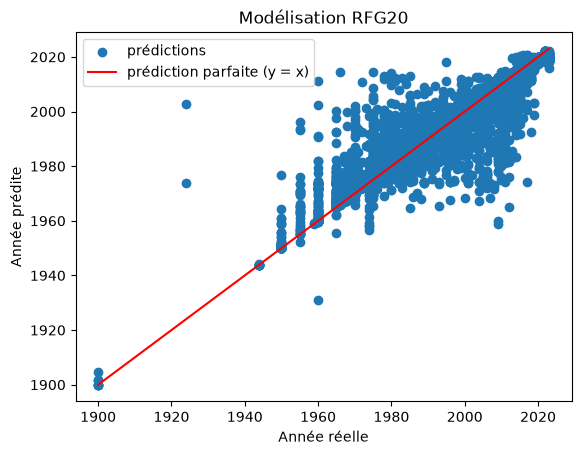

In [5]:
#Calcul des prédictions :
y_pred0 = model_0.predict(X_test)

# Visualisation des prédictions.
plt.scatter(y_test, y_pred0, label='prédictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
plt.legend()
plt.xlabel('Année réelle')
plt.ylabel('Année prédite')
plt.title('Modélisation RFG20')
plt.show()

## 4. 🌳 Modélisation avec GridSearchCV

Choisissons deux models de machine learning.

Évaluer les modèles avec optimisation (en testant différentes valeurs des hyperparamètres).
Optimisez les modèles comme vous le souhaitez, par exemple pour l'arbre des des decisions et forêt aléatoire :

### 🔍 Hyperparamètres testés
- `max_depth`: profondeur maximale des arbres [3, 4, 5, 10]
- `min_samples_leaf`: nombre minimum d'échantillons requis dans une feuille [0.1, 0.05]
- `n_estimators` (pour la forêt aléatoire uniquement) : nombre d'arbres dans la foret [50, 100, 200]

Utilisons GridSearchCV pour automatiser la recherche des meilleurs hyperparamètres.

In [6]:
#Optimisation des hyperparamètres avec RandomizedSearchCV et on peut imprimer les score MSE ou MAE de chaque cross-validation.
model_RS = Pipeline([
    ("prep", transformer),
    ("rfg", RandomForestRegressor(max_samples=0.5, random_state=28)),
])

#Je fais une RandomSearch pour explorer, et gridsearch quand j'aurais précisé mes hypothèses.
param_distributions = {
    'rfg__max_depth': [10, 20, 30, None],
    'rfg__min_samples_leaf': [1, 2, 5, 10],
    'rfg__n_estimators': [50, 100],
    'rfg__max_features': ['sqrt', 0.3, 0.5, 1.0]
}

forest_RS = RandomizedSearchCV(model_RS, param_distributions, n_iter=15, cv=3, scoring='neg_root_mean_squared_error', random_state=28, n_jobs=-1, return_train_score=True)
forest_RS.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=28))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'rfg__max_depth': [10, 20, ...], 'rfg__max_features': ['sqrt', 0.3, ...], 'rfg__min_samples_leaf': [1, 2, ...], 'rfg__n_estimators': [50, 100]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",28
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be use

In [7]:
print(-forest_RS.best_score_)
print(forest_RS.best_params_)

res = pd.DataFrame(forest_RS.cv_results_)

cols = ['param_rfg__max_depth', 'param_rfg__min_samples_leaf',
        'param_rfg__max_features', 'param_rfg__n_estimators',
        'mean_train_score', 'mean_test_score', 'std_test_score']

tab = res[cols].copy()
tab.columns = ['depth', 'leaf', 'max_feat', 'n_est', 'train_rmse', 'cv_rmse', 'cv_std']
tab[['train_rmse', 'cv_rmse']] = -tab[['train_rmse', 'cv_rmse']]

tab.sort_values('cv_rmse').round(2).head(10)


6.690999211212457
{'rfg__n_estimators': 100, 'rfg__min_samples_leaf': 1, 'rfg__max_features': 'sqrt', 'rfg__max_depth': None}


,depth,leaf,max_feat,n_est,train_rmse,cv_rmse,cv_std
1,None,1,sqrt,100,4.11,6.69,0.12
0,20,2,0.5,50,5.56,7.19,0.10
9,30,5,1.0,100,6.55,7.79,0.04
5,30,5,0.5,50,6.95,7.97,0.07
8,None,10,1.0,50,7.97,8.76,0.06
13,30,10,0.5,50,8.26,8.90,0.08
14,None,10,0.5,50,8.26,8.90,0.08
11,20,10,0.3,50,8.75,9.23,0.13
6,10,5,0.5,100,8.78,9.28,0.12
10,10,5,0.3,100,9.18,9.57,0.10


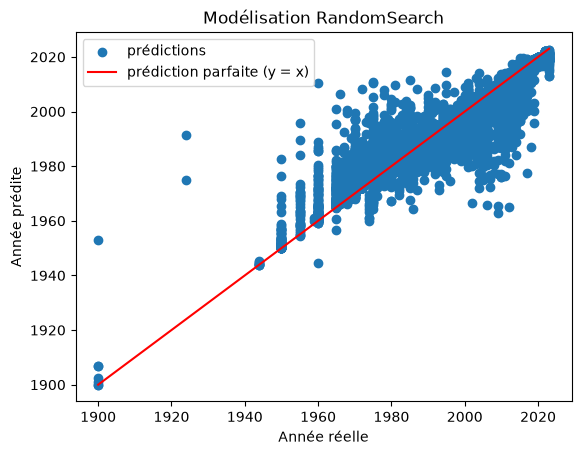

In [8]:
#Calcul des prédictions :
y_predRS = forest_RS.predict(X_test)

# Visualisation des prédictions.
plt.scatter(y_test, y_predRS, label='prédictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
plt.legend()
plt.xlabel('Année réelle')
plt.ylabel('Année prédite')
plt.title('Modélisation RandomSearch')
plt.show()

In [9]:
#Optimisation des hyperparamètres avec GridSearchCV et on peut imprimer les score MSE ou MAE de chaque cross-validation.
model_GS = Pipeline([
    ("prep", transformer),
    ("rfg", RandomForestRegressor(random_state=28)),
])

#Je fais une RandomSearch pour explorer, et gridsearch quand j'aurais précisé mes hypothèses.
param_grid = {
    'rfg__max_depth': [None],
    'rfg__min_samples_leaf': [1, 2],
    'rfg__n_estimators': [100],
    'rfg__max_features': ['sqrt', 0.2, 0.3, 0.5]
}

forest_GS = GridSearchCV(model_GS, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True)
forest_GS.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=28))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'rfg__max_depth': [None], 'rfg__max_features': ['sqrt', 0.2, ...], 'rfg__min_samples_leaf': [1, 2], 'rfg__n_estimators': [100]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only

In [10]:
print(-forest_GS.best_score_)
print(forest_GS.best_params_)

res = pd.DataFrame(forest_GS.cv_results_)

cols = ['param_rfg__max_depth', 'param_rfg__min_samples_leaf',
        'param_rfg__max_features', 'param_rfg__n_estimators',
        'mean_train_score', 'mean_test_score', 'std_test_score']

tab = res[cols].copy()
tab.columns = ['depth', 'leaf', 'max_feat', 'n_est', 'train_rmse', 'cv_rmse', 'cv_std']
tab[['train_rmse', 'cv_rmse']] = -tab[['train_rmse', 'cv_rmse']]

tab.sort_values('cv_rmse').round(2).head(10)


5.882804619025319
{'rfg__max_depth': None, 'rfg__max_features': 0.5, 'rfg__min_samples_leaf': 1, 'rfg__n_estimators': 100}


,depth,leaf,max_feat,n_est,train_rmse,cv_rmse,cv_std
6,None,1,0.5,100,2.19,5.88,0.26
4,None,1,0.3,100,2.20,5.91,0.27
2,None,1,0.2,100,2.21,5.92,0.22
0,None,1,sqrt,100,2.26,6.06,0.21
7,None,2,0.5,100,3.64,6.21,0.26
5,None,2,0.3,100,4.15,6.37,0.24
3,None,2,0.2,100,4.78,6.63,0.20
1,None,2,sqrt,100,8.18,8.80,0.14


## 5. Évaluation finale sur le set de test

In [78]:
# Code pour l'evaluation du meilleur modèle sur le set de test.
#Calcul des prédictions :
y_predGS = forest_GS.predict(X_test)

# RMSE de test des deux modèles
rmse_test0  = root_mean_squared_error(y_test, y_pred0)
rmse_testGS = root_mean_squared_error(y_test, y_predGS)

# Train RMSE du meilleur modèle GridSearch (moyenne sur les 5 plis)
train_rmseGS = -forest_GS.cv_results_['mean_train_score'][forest_GS.best_index_]

resultats = pd.DataFrame({
    'Train RMSE': [-cv0['train_score'].mean(), train_rmseGS],
    'CV RMSE':    [-cv0['test_score'].mean(),  -forest_GS.best_score_],
    'CV std':     [cv0['test_score'].std(),    forest_GS.cv_results_['std_test_score'][forest_GS.best_index_]],
    'Test RMSE':  [rmse_test0,                 rmse_testGS],
}, index=['Modèle 0 (depth=20)', 'GridSearch (best)'])

resultats.round(2)



,Train RMSE,CV RMSE,CV std,Test RMSE
Modèle 0 (depth=20),3.59,6.38,0.28,6.08
GridSearch (best),2.19,5.88,0.26,5.53


In [12]:
# Le modèle d'entrainement par GridSearch est meilleur(2.19 < 3.59)
# Il se trompe moins sur les nouvelles données (5.88 < 6.38)
# L'estimation est plus stable (0.26 < 0.28)
# Et la performance sur les nouvelles données est meilleure (5.53 < 6.08)

## 6. Visualisation des prédictions
Un seul model suffira.

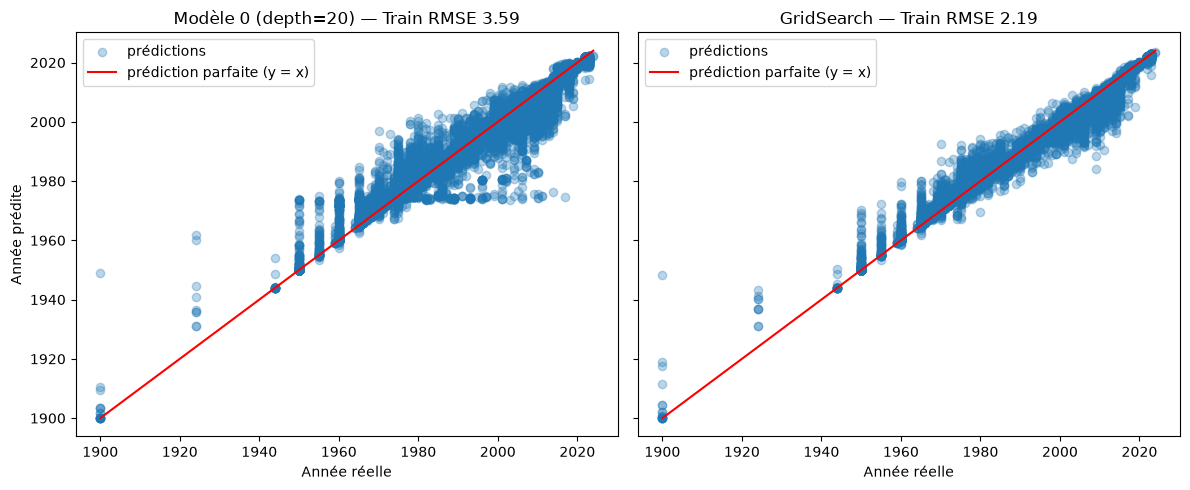

In [13]:
# Visualisation des prédictions.
y_train0 = model_0.predict(X_train)
y_trainGS = forest_GS.predict(X_train)
lims = [y_train.min(), y_train.max()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Graphique de gauche : modèle 0
axes[0].scatter(y_train, y_train0, alpha=0.3, label='prédictions')
axes[0].plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
axes[0].set_xlabel('Année réelle')
axes[0].set_ylabel('Année prédite')
axes[0].set_title(f'Modèle 0 (depth=20) — Train RMSE {-cv0['train_score'].mean():.2f}')
axes[0].legend()

# Graphique de droite : GridSearch
axes[1].scatter(y_train, y_trainGS, alpha=0.3, label='prédictions')
axes[1].plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
axes[1].set_xlabel('Année réelle')
axes[1].set_title(f'GridSearch — Train RMSE {train_rmseGS:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()   # un seul show, à la toute fin


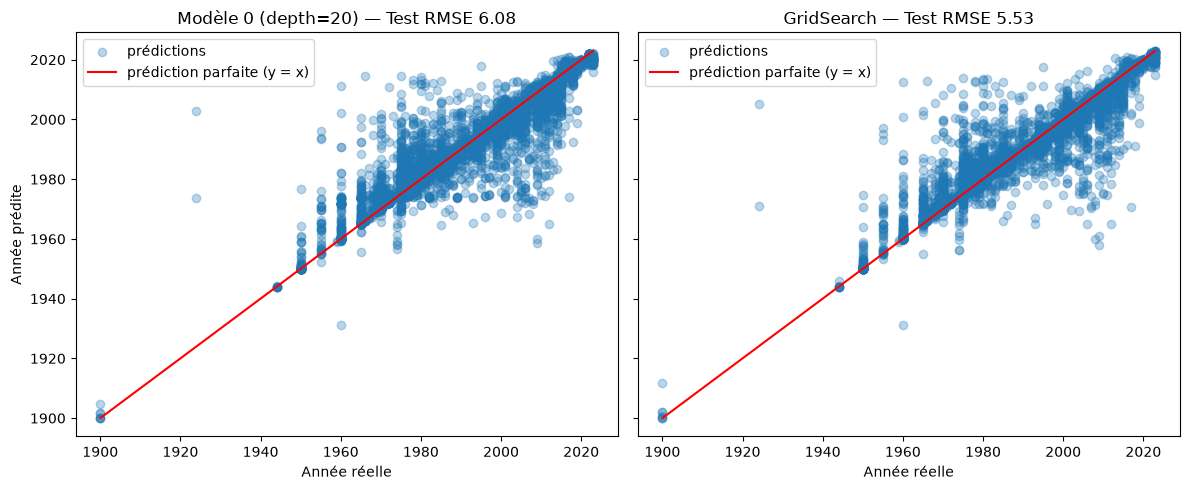

In [14]:
# Visualisation des prédictions.
lims = [y_test.min(), y_test.max()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

# Graphique de gauche : modèle 0
axes[0].scatter(y_test, y_pred0, alpha=0.3, label='prédictions')
axes[0].plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
axes[0].set_xlabel('Année réelle')
axes[0].set_ylabel('Année prédite')
axes[0].set_title(f'Modèle 0 (depth=20) — Test RMSE {rmse_test0:.2f}')
axes[0].legend()

# Graphique de droite : GridSearch
axes[1].scatter(y_test, y_predGS, alpha=0.3, label='prédictions')
axes[1].plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
axes[1].set_xlabel('Année réelle')
axes[1].set_title(f'GridSearch — Test RMSE {rmse_testGS:.2f}')
axes[1].legend()

plt.tight_layout()
plt.show()   # un seul show, à la toute fin


In [15]:
forest_GS.best_params_

{'rfg__max_depth': None,
 'rfg__max_features': 0.5,
 'rfg__min_samples_leaf': 1,
 'rfg__n_estimators': 100}

## 7. [OPTIONNEL] Importance des features

En utilisant la forêt aléatoire, comment peut-on savoir quelles sont les features les plus importantes ?

In [16]:
# Code, et à votre avis, comment etait calculé l'importance des features dans la forêt aléatoire ?
# Extract feature importances
best_pipe = forest_GS.best_estimator_
importances = best_pipe['rfg'].feature_importances_

feature_names = best_pipe['prep'].get_feature_names_out()
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

importance_par_variable = {}

for v in num_var + cat_var:
    # les colonnes qui appartiennent à la variable v
    morceaux = feature_importance_df['Feature'].str.contains('__' + v)
    # on additionne leur importance
    importance_par_variable[v] = feature_importance_df.loc[morceaux, 'Importance'].sum()

pd.Series(importance_par_variable).sort_values(ascending=False)

stadededeveloppement    0.375298
taxon                   0.167775
Longitude               0.122977
Latitude                0.121234
hauteurarbre            0.078391
adr_secteur             0.040562
typenature              0.040003
sous_categorie          0.032323
structure               0.021437
dtype: float64

Typiquement, on pourrait envisager de faire une backward elimination sur l'importance des features pour sélectionner le meilleur sous ensemble de features, mais cela peut-etre long si on a beaucoup de features et un modèle un peu long à entrainer comme c'est le cas ici. À la place on peut utiliser une regression avec regularisation lasso pour éliminer des features, avant de ré-entrainer une RandomForest sur les features sélectionnées. Créez un pipeline avec `LassoCV` comme selector et une RandomForest avec les meilleurs hyper-paramètres trouvés par la grid search en model. Évaluez sur le set de test.


In [17]:
# Code
full_pipeline = Pipeline([
    ("prep", transformer),
    ("selector", SelectFromModel(LassoCV(alphas=np.logspace(-4, 0, 20), cv=5, max_iter=10000))),
    ("rfg", RandomForestRegressor(random_state=28)),
])

full_pipeline.set_params(**forest_GS.best_params_)
full_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('selector', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['sous_categorie','adr_secteur','stadededeveloppement',...,'Latitude', 'Longitude','taxon']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_std', ...), ('cat_std', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed throu

In [18]:
# Combien de colonnes le Lasso a-t-il gardées ?
masque = full_pipeline['selector'].get_support()
print(f"Colonnes gardées : {masque.sum()} / {len(masque)}")

# Quel alpha le LassoCV a-t-il choisi ?
print(f"Alpha choisi : {full_pipeline['selector'].estimator_.alpha_}")


Colonnes gardées : 358 / 449
Alpha choisi : 0.00042813323987193956


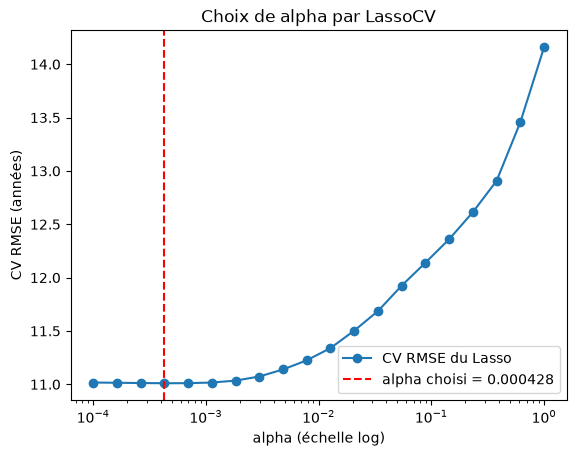

In [19]:
lasso = full_pipeline['selector'].estimator_

rmse_par_alpha = np.sqrt(lasso.mse_path_).mean(axis=1)

plt.plot(lasso.alphas_, rmse_par_alpha, marker='o', label='CV RMSE du Lasso')
plt.axvline(lasso.alpha_, color='r', linestyle='--', label=f'alpha choisi = {lasso.alpha_:.3g}')
plt.xscale('log')
plt.xlabel('alpha (échelle log)')
plt.ylabel('CV RMSE (années)')
plt.title('Choix de alpha par LassoCV')
plt.legend()
plt.show()


In [20]:
y_predL1 = full_pipeline.predict(X_test)
rmse_testL1 = root_mean_squared_error(y_test, y_predL1)

masque = full_pipeline['selector'].get_support()

resultats_lasso = pd.DataFrame({
    'alpha':            ['—', full_pipeline['selector'].estimator_.alpha_],
    'Colonnes gardées': [f"{len(masque)} / {len(masque)}", f"{masque.sum()} / {len(masque)}"],
    'Test RMSE':        [rmse_testGS, rmse_testL1],
}, index=['GridSearch (sans sélection)', 'LassoCV + RF'])

resultats_lasso.round({'Test RMSE': 2})


,alpha,Colonnes gardées,Test RMSE
GridSearch (sans sélection),—,449 / 449,5.53
LassoCV + RF,0.000428,358 / 449,5.57


## 8. [OPTIONNEL] Comparez différents modèles de regression

Comparez plus de modèles de régression entre eux (par exemple en plus de la régression linéaire, des arbres de décision et des forets, le `GradientBoostingRegressor`, et le plus récent `TabICLRegressor` si vous avez le temps ( https://github.com/soda-inria/tabicl )), en faisant une recherche d'hyperparamètre adéquate à chaque modèle :

In [21]:
#Optimisation des hyperparamètres avec GridSearchCV
model_ridge = Pipeline([
    ("prep", transformer),
    ("ridge", Ridge()),
])

param_grid = {
    'ridge__alpha': np.logspace(-2, 3, 20)
}

ridge_GS = GridSearchCV(model_ridge, param_grid, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True)
ridge_GS.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'ridge__alpha': array([1.0000...00000000e+03])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this s

In [88]:
#Optimisation des hyperparamètres avec GridSearchCV
model_dt = Pipeline([
    ("prep", transformer),
    ("dt", DecisionTreeRegressor(random_state=28)),
])

param_dt = {
    'dt__max_depth': [5, 10, 15, 20, 30, None],
    'dt__min_samples_leaf': [1, 5, 10, 20, 50]
}

model_DT = GridSearchCV(model_dt, param_dt, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True)
model_DT.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=28))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'dt__max_depth': [5, 10, ...], 'dt__min_samples_leaf': [1, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be det

In [98]:
#HistGradientBoostingRegressor
transformer_hgb = ColumnTransformer([
     ("num", "passthrough", num_var),
     ("cat", OrdinalEncoder(max_categories=250 ,handle_unknown='use_encoded_value', unknown_value=-1), cat_var)
])

cat_positions = list(range(len(num_var), len(num_var) + len(cat_var)))

pipe_hgb = Pipeline([
    ("prep", transformer_hgb),
    ("hgb", HistGradientBoostingRegressor(categorical_features=cat_positions, max_iter=1000, random_state=28)),
])

param_hgb = {
    'hgb__learning_rate': sp.loguniform(0.03, 0.06),
    'hgb__max_leaf_nodes': [127, 255, 511],
    'hgb__l2_regularization': [0, 2.5, 5],
    'hgb__min_samples_leaf': [2, 3, 5]
}

model_HGB = RandomizedSearchCV(pipe_hgb, param_hgb, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True, random_state=28, n_iter =30)
model_HGB.fit(X_train, y_train)


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=28))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'hgb__l2_regularization': [0, 2.5, ...], 'hgb__learning_rate': <scipy.stats....x7c2bfafd4050>, 'hgb__max_leaf_nodes': [127, 255, ...], 'hgb__min_samples_leaf': [2, 3, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",28
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denotin

In [102]:
#HistGradientBoostingRegressor
pipe_hgbGS = Pipeline([
    ("prep", transformer_hgb),
    ("hgb", HistGradientBoostingRegressor(categorical_features=cat_positions, max_iter=2000, random_state=28)),
])

param_hgbGS = {
    'hgb__learning_rate': [0.04, 0.06, 0.08],
    'hgb__max_leaf_nodes': [63, 127, 255],
    'hgb__l2_regularization': [0],
    'hgb__min_samples_leaf': [3, 5, 10]
}

model_HGBGS = GridSearchCV(pipe_hgbGS, param_hgbGS, cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1, return_train_score=True)
model_HGBGS.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=28))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'hgb__l2_regularization': [0], 'hgb__learning_rate': [0.04, 0.06, ...], 'hgb__max_leaf_nodes': [63, 127, ...], 'hgb__min_samples_leaf': [3, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``bes

In [119]:
#TabICLRegressor

model_tabicl = TabICLRegressor()
tabicl_cv = cross_validate(model_tabicl, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')

/home/sami.chircop@Digital-Grenoble.local/anaconda3/lib/python3.14/site-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['taxon']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(
/home/sami.chircop@Digital-Grenoble.local/anaconda3/lib/python3.14/site-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['taxon']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(
/home/sami.chircop@Digital-Grenoble.local/anaconda3/lib/python3.14/site-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['taxon']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skru

/home/sami.chircop@Digital-Grenoble.local/anaconda3/lib/python3.14/site-packages/tabicl/_sklearn/preprocessing.py:138: UserWarning: The following categorical columns have a cardinality above 40: ['taxon']. High-cardinality columns might benefit from a better encoding than ordinal encoding, e.g. Skrub's TableVectorizer for strings.
  warnings.warn(


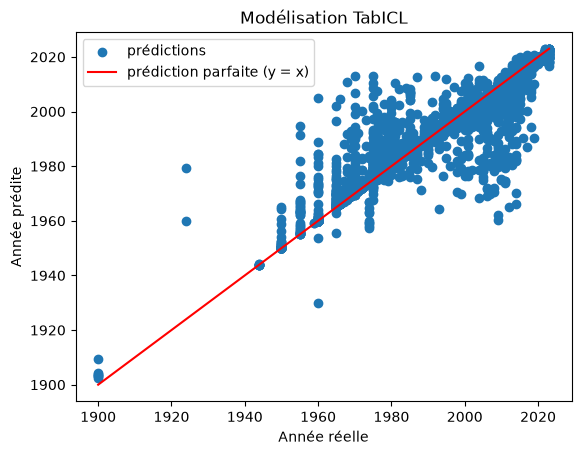

In [125]:
#Calcul des prédictions :
model_tabicl.fit(X_train, y_train)
y_predtTabicl = model_tabicl.predict(X_test)

# Visualisation des prédictions.
plt.scatter(y_test, y_predtTabicl, label='prédictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
plt.legend()
plt.xlabel('Année réelle')
plt.ylabel('Année prédite')
plt.title('Modélisation TabICL')
plt.show()

Choisissez le modèle qui marche le mieux et ses meilleurs hyper-paramètres, sélectionnez le meilleur sous-ensemble de features pour ce modèle, et enfin refaites une dernière grid-search sur les hyper-paramètres de votre modèle avec les features retenues, pour obtenir votre modèle final. Évaluez sur le test set.

In [ ]:
# # Backward selection : on retire une variable à la fois et on refait la CV
# import warnings
# warnings.filterwarnings('ignore', message='.*cardinality above 40.*')

# resultats_drop = {}

# for col in X_train.columns:
#     x_opti = X_train.drop(columns=col)          # copie de X_train sans la colonne col
#     model_opti = TabICLRegressor(n_estimators=4)
#     temp = cross_validate(model_opti, x_opti, y_train, cv=5,
#                           scoring='neg_root_mean_squared_error')
#     resultats_drop[col] = {'CV RMSE sans': -temp['test_score'].mean(),
#                            'CV std':        temp['test_score'].std()}
#     print(f"{col} retirée → CV RMSE {resultats_drop[col]['CV RMSE sans']:.2f}")

# cv_rmse_bcksel = pd.DataFrame(resultats_drop).T
# cv_rmse_bcksel['Écart'] = cv_rmse_bcksel['CV RMSE sans'] - cv_rmse_tabicl
# cv_rmse_bcksel.sort_values('Écart').round(2)


sous_categorie retirée → CV RMSE 5.09
adr_secteur retirée → CV RMSE 4.99
stadededeveloppement retirée → CV RMSE 5.91
hauteurarbre retirée → CV RMSE 5.05
structure retirée → CV RMSE 5.07
typenature retirée → CV RMSE 5.03
Latitude retirée → CV RMSE 6.07
Longitude retirée → CV RMSE 5.97
taxon retirée → CV RMSE 5.95


,CV RMSE sans,CV std,Écart
adr_secteur,4.99,0.19,0.07
typenature,5.03,0.18,0.11
hauteurarbre,5.05,0.23,0.13
structure,5.07,0.21,0.14
sous_categorie,5.09,0.16,0.17
stadededeveloppement,5.91,0.31,0.99
taxon,5.95,0.22,1.02
Longitude,5.97,0.23,1.05
Latitude,6.07,0.17,1.14


In [151]:
#TabICLRegressor
model_tabicl = TabICLRegressor(n_estimators=16)
model_tabicl.fit(X_train, y_train)
y_predtfinal= model_tabicl.predict(X_test)

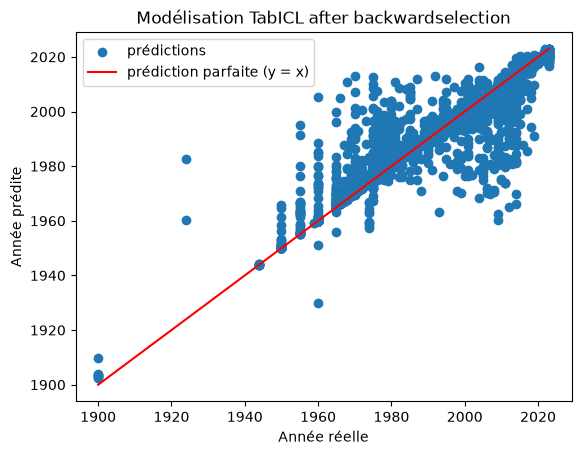

In [152]:
# Visualisation des prédictions.
plt.scatter(y_test, y_predtfinal, label='prédictions')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r', label='prédiction parfaite (y = x)')
plt.legend()
plt.xlabel('Année réelle')
plt.ylabel('Année prédite')
plt.title('Modélisation TabICL after backwardselection')
plt.show()

## Conclusion

In [153]:
def scores_recherche(search):
    """Extrait les scores du meilleur modèle d'un GridSearchCV / RandomizedSearchCV."""
    i = search.best_index_
    return {
        'Train RMSE': -search.cv_results_['mean_train_score'][i],
        'CV RMSE':    -search.best_score_,
        'CV std':      search.cv_results_['std_test_score'][i],
    }

comparaison = pd.DataFrame(columns=['Train RMSE', 'CV RMSE', 'CV std'])

# La forêt est déjà faite : on l'ajoute directement
comparaison.loc['DecisionTree'] = scores_recherche(model_DT)
comparaison.loc['RandomForest'] = scores_recherche(forest_GS)
comparaison.loc['Ridge'] = scores_recherche(ridge_GS)
comparaison.loc['HistGradBoost'] = scores_recherche(model_HGBGS)

# Scores de TabICL (CV à 5 plis)
cv_rmse_tabicl = -tabicl_cv['test_score'].mean()
cv_std_tabicl  =  tabicl_cv['test_score'].std()
# Score de train : seulement s'il a été calculé
if 'train_score' in tabicl_cv:
    train_rmse_tabicl = -tabicl_cv['train_score'].mean()
else:
    train_rmse_tabicl = np.nan
print(f"CV RMSE : {cv_rmse_tabicl:.2f} ± {cv_std_tabicl:.2f}")
print(f"Temps moyen par pli : fit {tabicl_cv['fit_time'].mean():.1f} s, predict {tabicl_cv['score_time'].mean():.1f} s")
# Ajout au tableau de comparaison
comparaison.loc['TabICL'] = {'Train RMSE': train_rmse_tabicl,
                             'CV RMSE':    cv_rmse_tabicl,
                             'CV std':     cv_std_tabicl}

comparaison.round(2).sort_values('CV RMSE')

CV RMSE : 4.91 ± 0.18
Temps moyen par pli : fit 0.5 s, predict 7.6 s


,Train RMSE,CV RMSE,CV std
TabICL,NaN,4.91,0.18
HistGradBoost,2.32,5.73,0.21
RandomForest,2.19,5.88,0.26
DecisionTree,-0.00,7.62,0.32
Ridge,10.79,11.00,0.12
